# Example: Updating the Single Index Model and the Preference Weights
In this example, we update the single index model of every stock with each trading day of 2025 and 2026, starting from the 2014 to 2024 fit. We use the updated estimates to compute each stock's preference weight $\gamma_{i}(t)$, and pick a basket of the stocks with the highest preference weights in each sector. This is how the trading method of [Varner (2026)](https://arxiv.org/abs/2611.03022) chooses its stocks.

Then we pick the basket again from the fixed 2014 to 2024 estimates, and compare the two baskets.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Update the single index model every day:__ Start from the 2014 to 2024 fit, and update each stock's baseline $\alpha_{i}$ and market sensitivity $\beta_{i}$ with each new trading day. Compare the updated market sensitivity of a stock we choose with its fixed estimate.
> * __Pick the γ basket when the market turns:__ Compute the preference weight of every stock from the updated estimates and the market state $\xi_{t}$. Pick the stocks with the highest preference weights in each sector once a month, and again whenever the market turns.
> * __Compare the updated and fixed baskets:__ Pick the basket again from the fixed 2014 to 2024 estimates. Compare the market sensitivity of the two baskets, and count the stocks they share.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, and loads the functions in the local `src` directory. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating 

project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/). The `MPC` module of the course package holds the code of the trading method.

### Data
We load daily prices from January 3, 2014, to November 13, 2026, and each firm's sector in the [Global Industry Classification Standard (GICS)](https://www.msci.com/our-solutions/indexes/gics) with [the `MPC.load_market_data(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.load_market_data-Tuple{String}). The universe is every stock with a price on every trading day over those dates and a GICS sector. [The `Logging.global_logger(...)` function](https://docs.julialang.org/en/v1/stdlib/Logging/#Logging.global_logger) turns off the loader's notes about stock splits while it runs.

We store the data in the [`md::MPC.MyMarketData` variable](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.MyMarketData). The `md.dates` field holds the trading days, `md.tickers` the stock tickers in alphabetical order, and `md.sector` the sector of each stock. The `md.close` field holds the closing prices (days × tickers, USD/share), and `md.spy_close` the closing prices of `SPY`:

In [2]:
md = let

    # load the prices and sectors: every stock with a full price history from 2014 through November 13, 2026 -
    logger = Logging.global_logger(Logging.NullLogger()); # turn off the loader's notes, and keep the old logger
    md = MPC.load_market_data(_PATH_TO_MARKET_DATA; start = Date(2014, 1, 3), stop = Date(2026, 11, 13),
        files = MPC.DATA_FILES_NOV2026);
    Logging.global_logger(logger); # turn the notes back on

    # checks -
    @assert md.dates[1] == Date(2014, 1, 3) && md.dates[end] == Date(2026, 11, 13) "the data must run from 2014-01-03 to 2026-11-13"
    @assert size(md.close) == (length(md.dates), length(md.tickers)) "one closing price per trading day and ticker"
    @assert all(md.close .> 0) "every stock must have a price on every trading day"

    # return -
    md
end;
println("$(length(md.tickers)) stocks in $(length(unique(md.sector))) sectors, $(length(md.dates)) trading days");

373 stocks in 11 sectors, 3236 trading days


### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values:

In [3]:
train_start = Date(2014, 1, 3); # first trading day of the fitting period
train_stop = Date(2024, 12, 31); # last trading day of the fitting period
run_start = Date(2025, 1, 2); # first trading day we update on
run_stop = Date(2026, 11, 13); # last trading day of the data
half_life = 63.0; # trading days for the weight of one day of data to halve in the update; 63 is about one quarter
prior_weight = 63.0; # weight of the 2014 to 2024 fit when the updates start, counted in trading days of data
β_floor = 0.1; # smallest |β| in the denominator of the preference weight (dimensionless)
N_per_sector = 3; # stocks picked in each sector (count)
repick_interval = 21; # trading days between scheduled picks; 21 is about one month
my_ticker = "JPM"; # the stock we follow in Task 1; any ticker in md.tickers

___

## Task 1: Update the Single Index Model Every Day
In this task, we fit the single index model of every stock on 2014 to 2024, then update each stock's estimates with every trading day of 2025 and 2026. In this block, we explain the update method and the code that implements it.

* [The `MPC.calibrate(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.calibrate-Tuple{VLQuantitativeFinancePackage.MPCPortfolio.MyMarketData}) fits the single index model of each stock by least squares on the growth rates of the fitting period. These fixed estimates $(\hat{\alpha}_{i},\hat{\beta}_{i})$ are the ones our preference weights used before. The function also computes inputs that the trading method needs later, which we do not use here.
* [The `MPC.online_sim(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.online_sim-Tuple{VLQuantitativeFinancePackage.MPCPortfolio.MyMarketData,%20VLQuantitativeFinancePackage.MPCPortfolio.MyCalibration}) then updates the estimates of every stock with each trading day of 2025 and 2026. Each day, the update multiplies the weight of all earlier data by the factor $\phi$ and adds the new day with weight one. We choose $\phi$ so that the weight of one day of data halves every `half_life` trading days. The 2014 to 2024 fit enters at the start as `prior_weight` trading days of data, and its weight decays the same way.

We store the fit in the `calib::MPC.MyCalibration` variable and the updates in the `sim::MPC.MyOnlineSIM` variable. The `sim.α` and `sim.β` fields hold the updated estimates (run days × tickers), and `sim.rows` holds the row of each run day in `md`:

In [ ]:
calib, sim = let

    # fit the single index model of every stock on 2014 to 2024 (the fixed estimates) -
    calib = MPC.calibrate(md; train_start = train_start, train_stop = train_stop);

    # update the estimates of every stock with each trading day of 2025 and 2026 -
    sim = MPC.online_sim(md, calib; start = run_start, stop = run_stop, half_life = half_life,
        prior_weight = prior_weight);

    # checks -
    @assert md.dates[first(sim.rows)] == run_start && md.dates[last(sim.rows)] == run_stop "one row of sim per run day"
    @assert size(sim.β) == (length(sim.rows), length(md.tickers)) "one updated β per run day and stock"
    @assert all(isfinite, sim.α) && all(isfinite, sim.β) "every updated estimate must be a number"

    # return -
    calib, sim
end;

Let's plot the updated market sensitivity $\beta_{i}(t)$ of the `my_ticker` stock over 2025 and 2026 with [the `plot(...)` function](https://docs.juliaplots.org/stable/api/#RecipesBase.plot). The dashed line is its fixed estimate $\hat{\beta}_{i}$:

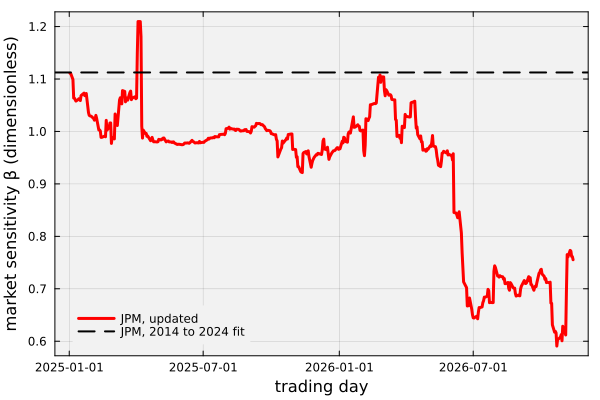

In [5]:
let

    # initialize: the column of my_ticker (1 is a placeholder, so a bad my_ticker still reaches the checks) -
    matches = findall(md.tickers .== my_ticker); # positions of my_ticker in md.tickers
    j = 1;
    if length(matches) == 1
        j = matches[1];
    end
    run_dates = md.dates[sim.rows]; # the trading days of 2025 and 2026
    β_updated = sim.β[:, j]; # updated β on each run day (dimensionless)
    β_fixed = calib.base_sim[md.tickers[j]].β; # the 2014 to 2024 estimate (dimensionless)

    # display options used in this cell -
    # lw: Set the line width in points.
    # c: Choose the series color.
    # ls: Choose the line style; :dash draws a dashed line.
    # label: Set the legend entry.
    # bg: Set the plot background color.
    # background_color_outside: Set the background color outside the plotting grid.
    # framestyle: Use a box around the plotting area.
    # fg_legend: Set the legend foreground color; transparent removes its border.
    # legend: Place the legend inside the plotting area.
    p = plot(run_dates, β_updated, lw = 3, c = :red, label = "$(my_ticker), updated",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legend = :best);
    hline!(p, [β_fixed], lw = 2, c = :black, ls = :dash, label = "$(my_ticker), 2014 to 2024 fit");
    xlabel!(p, "trading day");
    ylabel!(p, "market sensitivity β (dimensionless)");

    # checks -
    @assert length(matches) == 1 "my_ticker must be one of the tickers in md.tickers"

    # return -
    p
end

Next, let's compare the fixed and updated market sensitivities of every stock on the last trading day with [the `scatter!(...)` function](https://docs.juliaplots.org/stable/api/#Plots.scatter!-Tuple). Each point is one stock. A stock on the dashed line has the same estimate in both, and a stock below the dashed line has a lower updated market sensitivity:

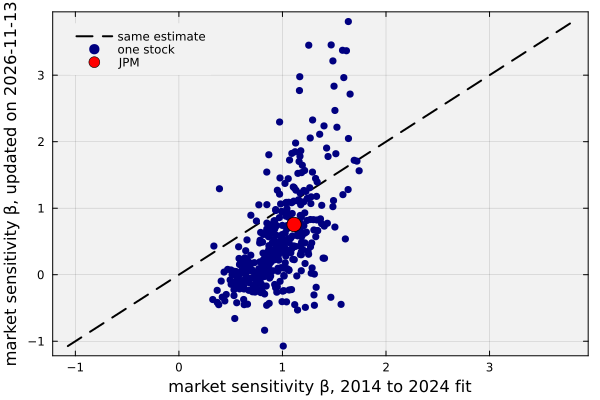

In [6]:
let

    # initialize: the fixed and the last updated β of every stock -
    number_of_stocks = length(md.tickers);
    β_fixed = zeros(number_of_stocks); # the 2014 to 2024 estimates (dimensionless)
    for j ∈ 1:number_of_stocks
        β_fixed[j] = calib.base_sim[md.tickers[j]].β;
    end
    β_last = sim.β[end, :]; # the updated estimates on the last run day (dimensionless)

    # the column of my_ticker (1 is a placeholder, so a bad my_ticker still reaches the checks) -
    matches = findall(md.tickers .== my_ticker);
    k = 1;
    if length(matches) == 1
        k = matches[1];
    end

    # the dashed line where the two estimates are equal, across the range of both -
    β_low = min(minimum(β_fixed), minimum(β_last));
    β_high = max(maximum(β_fixed), maximum(β_last));

    # display options used in this cell (see the previous plot for the others) -
    # ms: Set the marker size in points.
    # msc: Set the marker outline color.
    p = plot([β_low, β_high], [β_low, β_high], lw = 2, c = :black, ls = :dash, label = "same estimate",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legend = :topleft);
    scatter!(p, β_fixed, β_last, ms = 4, c = :navy, msc = :navy, label = "one stock");
    scatter!(p, [β_fixed[k]], [β_last[k]], ms = 8, c = :red, msc = :black, label = my_ticker);
    xlabel!(p, "market sensitivity β, 2014 to 2024 fit");
    ylabel!(p, "market sensitivity β, updated on $(md.dates[sim.rows[end]])");

    # checks -
    @assert length(matches) == 1 "my_ticker must be one of the tickers in md.tickers"

    # return -
    p
end

> __What do we see?__ Most stocks sit below the dashed line. In late 2026, most stocks moved less with the market than they did from 2014 to 2024. A preference weight built on the fixed estimates treats these stocks as more sensitive to the market than they are now.

___

## Task 2: Pick the γ Basket When the Market Turns
In this task, we compute the preference weight of every stock on every trading day from the updated estimates, and pick the γ basket on each pick day.

We compute the market inputs from the closing prices of `SPY`. [The `MPC.xi_gain(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.xi_gain-Tuple{AbstractVector}) chooses the gain $G$ from the 2014 to 2024 closes. [The `MPC.xi_series(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.xi_series-Tuple{AbstractVector}) gives the market state $\xi_{t}$, and [the `MPC.gtilde_series(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.gtilde_series-Tuple{AbstractVector}) gives the recent market growth rate $\tilde{g}_{M,t}$.

[The `MPC.gamma_weights(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.gamma_weights-Tuple{AbstractVector,%20AbstractVector,%20Real,%20Real}) then computes the preference weight $\gamma_{i}(t)$ of every stock from its updated estimates.

We store the market state on each run day in the `ξ_run::Array{Float64,1}` array, the recent market growth rate in the `g̃_run::Array{Float64,1}` array (1/yr), and the preference weights in the `γ_updated::Array{Float64,2}` array (run days × tickers):

In [7]:
ξ_run, g̃_run, γ_updated = let

    # the market inputs on every trading day: the gain G from the 2014 to 2024 closes of SPY, then ξ and g̃ -
    k_stop = findlast(md.dates .<= train_stop); # row of the last fitting day
    G = MPC.xi_gain(md.spy_close[1:k_stop]); # chosen so that |ξ| ≤ 1 on 99% of the fitting days
    ξ = MPC.xi_series(md.spy_close; G = G); # market state on every trading day (dimensionless)
    g̃ = MPC.gtilde_series(md.spy_close); # recent market growth rate on every trading day (1/yr)

    # the preference weight of every stock on every run day, from the updated estimates -
    number_of_run_days = length(sim.rows);
    ξ_run = zeros(number_of_run_days);
    g̃_run = zeros(number_of_run_days);
    γ_updated = zeros(number_of_run_days, length(md.tickers));
    for s ∈ 1:number_of_run_days
        t = sim.rows[s]; # row of run day s in md
        ξ_run[s] = ξ[t];
        g̃_run[s] = g̃[t];
        γ_updated[s, :] = MPC.gamma_weights(sim.α[s, :], sim.β[s, :], g̃[t], ξ[t]; β_floor = β_floor);
    end

    # checks -
    @assert all(isfinite, ξ_run) && all(isfinite, g̃_run) "every market input must be a number"
    @assert all(abs.(γ_updated) .< 1) "every preference weight must lie between -1 and 1"

    # return -
    ξ_run, g̃_run, γ_updated
end;

Next, we pick the γ basket. [The `pick_days(...)` function](src/Helper.jl) returns the first run day, each day `repick_interval` trading days after the last pick, and each day the market turns. The market turns when the market state $\xi_{t}$ moves to the other side of zero from its value on the last pick day.

On each pick day, [the `gamma_basket(...)` function](src/Helper.jl) picks the `N_per_sector` stocks with the highest preference weights in each sector.

We store the picks in the [`picks_updated::DataFrame` variable](https://dataframes.juliadata.org/stable/lib/types/#DataFrames.DataFrame). Each row holds the date, the reason for the pick, the position of the pick day among the run days, and the market state. It also holds the [average](https://docs.julialang.org/en/v1/stdlib/Statistics/#Statistics.mean) updated $\beta_{i}$ of the basket and of all stocks, and the positions of the basket's stocks in `md.tickers`:

In [8]:
picks_updated = let

    # the pick days: the first run day, every repick_interval trading days, and every market turn -
    picks = pick_days(ξ_run; repick_interval = repick_interval);

    # the γ basket of each pick day, and the average updated β of the basket and of all stocks -
    df = DataFrame(date = Date[], reason = String[], day = Int[], ξ = Float64[], β_basket = Float64[],
        β_all = Float64[], basket = Vector{Int}[]);
    for k ∈ 1:length(picks.day)
        s = picks.day[k]; # position of the pick day among the run days
        basket = gamma_basket(γ_updated[s, :], md.sector; N = N_per_sector);
        push!(df, (md.dates[sim.rows[s]], picks.reason[k], s, ξ_run[s], mean(sim.β[s, basket]), mean(sim.β[s, :]), basket));
    end
    println("$(nrow(df)) pick days: $(count(df.reason .== "scheduled")) scheduled and $(count(df.reason .== "market turn")) at a market turn, after the first");

    # checks -
    @assert nrow(df) == length(picks.day) "one row per pick day"
    @assert all(length.(df.basket) .== N_per_sector * length(unique(md.sector))) "N_per_sector stocks from each sector"

    # return -
    df
end;

25 pick days: 20 scheduled and 4 at a market turn, after the first


Let's plot the market state $\xi_{t}$ with the average updated market sensitivity of the γ basket and of all stocks. Each average holds from its pick day to the next pick day. The circles mark the picks made when the market turned:

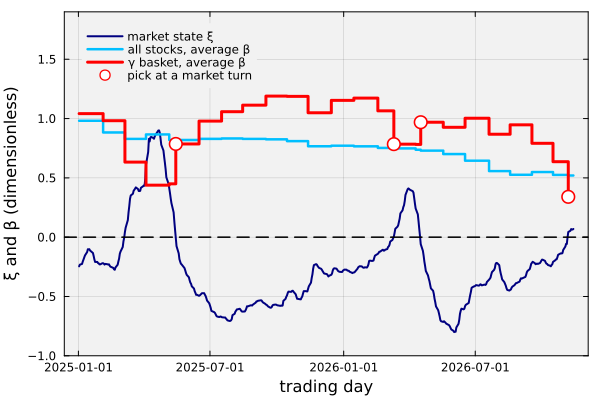

In [9]:
let

    # initialize: each average holds from its pick day to the next pick day, and the last one to the end of the data -
    run_dates = md.dates[sim.rows]; # the trading days of 2025 and 2026
    step_dates = vcat(picks_updated.date, run_dates[end]);
    β_basket = vcat(picks_updated.β_basket, picks_updated.β_basket[end]); # average β of the γ basket
    β_all = vcat(picks_updated.β_all, picks_updated.β_all[end]); # average β of all stocks
    turns = findall(picks_updated.reason .== "market turn"); # rows of the picks made at a market turn

    # display options used in this cell (see the first plot for the others) -
    # seriestype: :steppost holds each value until the next date.
    # msw: Set the marker outline width in points.
    # ylims: Set the y-axis range; the top leaves room for the legend above the data.
    p = plot(run_dates, ξ_run, lw = 2, c = :navy, label = "market state ξ", ylims = (-1.0, 1.9),
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legend = :topleft);
    hline!(p, [0.0], lw = 1.5, c = :black, ls = :dash, label = "");
    plot!(p, step_dates, β_all, seriestype = :steppost, lw = 2.5, c = :deepskyblue1, label = "all stocks, average β");
    plot!(p, step_dates, β_basket, seriestype = :steppost, lw = 3, c = :red, label = "γ basket, average β");
    scatter!(p, picks_updated.date[turns], picks_updated.β_basket[turns], ms = 7, c = :white, msc = :red, msw = 2,
        label = "pick at a market turn");
    xlabel!(p, "trading day");
    ylabel!(p, "ξ and β (dimensionless)");

    # return -
    p
end

> __What do we see?__ When the market fell in the spring of 2025 ($\xi_{t}>0$), the average market sensitivity of the γ basket dropped well below the average of all stocks. The preference weight favored stocks that move less with the market. This is the bet of the [betting-against-beta portfolio](https://www.aqr.com/Insights/Research/Journal-Article/Betting-Against-Beta) of Frazzini and Pedersen (2014).
>
> When the market rose through the rest of 2025 ($\xi_{t}<0$), the basket's average market sensitivity sat above the average of all stocks.

Finally, let's list the γ basket of the last pick day with [the `pretty_table(...)` function](https://ronisbr.github.io/PrettyTables.jl/stable/lib/library/#PrettyTables.pretty_table). These are the stocks the trading method would choose from at the end of the data. The table lists each stock's sector, its preference weight, and its updated and fixed market sensitivities:

In [10]:
let

    # initialize: the last pick day and its basket -
    k = nrow(picks_updated);
    s = picks_updated.day[k]; # position of the last pick day among the run days
    basket = picks_updated.basket[k]; # positions of the basket's stocks in md.tickers

    # one row per stock, in sector order -
    df = DataFrame(sector = String[], ticker = String[], γ = Float64[], β_updated = Float64[], β_fixed = Float64[]);
    for sector ∈ sort(unique(md.sector))
        for j ∈ basket
            if md.sector[j] == sector
                push!(df, (sector, md.tickers[j], γ_updated[s, j], sim.β[s, j], calib.base_sim[md.tickers[j]].β));
            end
        end
    end
    println("the γ basket of $(picks_updated.date[k])");

    # let's display the basket in a table -
    pretty_table(df;
        column_labels = ["sector", "ticker", "γ", "β, updated", "β, 2014 to 2024"], # displayed column headings
        alignment = [:l, :l, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [3, 4, 5])], # print the numeric columns to three decimal places
        table_format = TextTableFormat(borders = text_table_borders__compact), # compact separator characters
        fit_table_in_display_horizontally = false, # keep all columns
        fit_table_in_display_vertically = false # keep all rows
    );
end

the γ basket of 2026-11-06


 ------------------------ -------- ------- ------------ -----------------
  sector                   ticker       γ   β, updated   β, 2014 to 2024 
 ------------------------ -------- ------- ------------ -----------------
  Communication Services   DIS      0.305        0.445             0.998
  Communication Services   FOXA     0.196        0.298             0.812
  Communication Services   OMC      0.269        0.294             0.893
  Consumer Discretionary   BBY      0.550        0.605             1.104
  Consumer Discretionary   HAS      0.638        0.570             0.940
  Consumer Discretionary   ULTA     0.469        0.520             1.053
  Consumer Staples         EL       0.483        1.133             1.037
  Consumer Staples         KO       0.364       -0.239             0.586
  Consumer Staples         TGT      0.398        0.376             0.808
  Energy                   MPC      0.492       -0.148             1.278
  Energy                   PSX      0.448       

___

## Task 3: Compare the Updated and Fixed Baskets
In this task, we pick the γ basket again from the fixed 2014 to 2024 estimates, and compare it with the basket of Task 2.

We compute the preference weights from the fixed estimates $(\hat{\alpha}_{i},\hat{\beta}_{i})$ with the same market inputs, and pick on the same days. The pick days depend only on the market state, and they stay the same. We measure the market sensitivity of both baskets with the updated estimates, which describe how each stock moves with the market on the pick day.

We store the result in the `picks_fixed::DataFrame` variable. Each row holds the date, the average updated $\beta_{i}$ of the fixed basket, and the number of stocks the two baskets share, from [the `intersect(...)` function](https://docs.julialang.org/en/v1/base/collections/#Base.intersect):

In [11]:
picks_fixed = let

    # initialize: the fixed 2014 to 2024 estimates of every stock -
    number_of_stocks = length(md.tickers);
    α_fixed = zeros(number_of_stocks); # baseline (1/yr)
    β_fixed = zeros(number_of_stocks); # market sensitivity (dimensionless)
    for j ∈ 1:number_of_stocks
        α_fixed[j] = calib.base_sim[md.tickers[j]].α;
        β_fixed[j] = calib.base_sim[md.tickers[j]].β;
    end

    # the fixed basket of each pick day, measured with the updated β -
    df = DataFrame(date = Date[], β_basket = Float64[], shared = Int[]);
    for k ∈ 1:nrow(picks_updated)
        s = picks_updated.day[k]; # position of the pick day among the run days
        γ_fixed = MPC.gamma_weights(α_fixed, β_fixed, g̃_run[s], ξ_run[s]; β_floor = β_floor);
        basket = gamma_basket(γ_fixed, md.sector; N = N_per_sector);
        shared = length(intersect(basket, picks_updated.basket[k])); # stocks in both baskets
        push!(df, (picks_updated.date[k], mean(sim.β[s, basket]), shared));
    end
    println("On an average pick day, the two baskets share $(round(mean(df.shared), digits = 1)) of $(length(picks_updated.basket[1])) stocks.");

    # checks -
    @assert nrow(df) == nrow(picks_updated) "one row per pick day"

    # return -
    df
end;

On an average pick day, the two baskets share 7.6 of 33 stocks.


Let's plot the average updated market sensitivity of the two baskets and of all stocks:

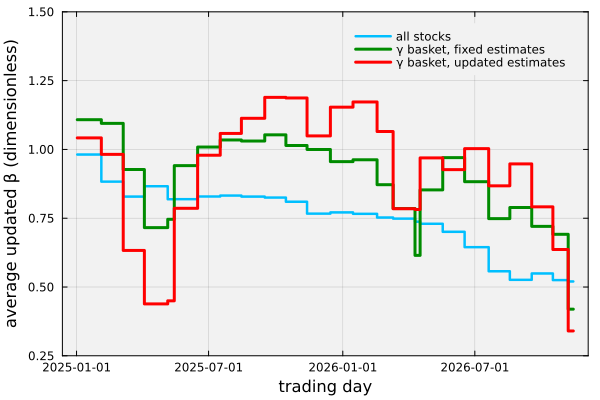

In [12]:
let

    # initialize: each average holds from its pick day to the next pick day, and the last one to the end of the data -
    run_dates = md.dates[sim.rows];
    step_dates = vcat(picks_updated.date, run_dates[end]);
    β_updated_basket = vcat(picks_updated.β_basket, picks_updated.β_basket[end]); # basket from the updated estimates
    β_fixed_basket = vcat(picks_fixed.β_basket, picks_fixed.β_basket[end]); # basket from the fixed estimates
    β_all = vcat(picks_updated.β_all, picks_updated.β_all[end]); # all stocks

    # plot: the three averages (see the earlier plots for the display options) -
    p = plot(step_dates, β_all, seriestype = :steppost, lw = 2.5, c = :deepskyblue1, label = "all stocks", ylims = (0.25, 1.5),
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legend = :topright);
    plot!(p, step_dates, β_fixed_basket, seriestype = :steppost, lw = 3, c = :green4, label = "γ basket, fixed estimates");
    plot!(p, step_dates, β_updated_basket, seriestype = :steppost, lw = 3, c = :red, label = "γ basket, updated estimates");
    xlabel!(p, "trading day");
    ylabel!(p, "average updated β (dimensionless)");

    # return -
    p
end

> __What do we see?__ The two baskets share few stocks, and they share fewer in 2026 than in 2025. The longer we keep the 2014 to 2024 estimates, the further they drift from how the stocks move now.
>
> The market sensitivity of the updated basket also swings more with the market state. Its preference weights use each stock's market sensitivity as it is on the pick day.

___

## Summary
In this example, we updated the single index model of every stock with each trading day, picked the γ basket from the updated preference weights, and compared it with the basket from the fixed estimates.

> __Key Takeaways:__
>
> * __Market sensitivity changes over time:__ We started from the 2014 to 2024 fit and updated each stock's estimates with every trading day of 2025 and 2026. By late 2026, most stocks moved less with the market than their fixed estimates say.
> * __The preference weight tilts with the market state:__ We picked the stocks with the highest preference weights in each sector once a month and whenever the market turned. When the market fell, the basket favored stocks with a low market sensitivity, the bet of betting against beta.
> * __Updating changes the basket:__ The fixed estimates picked a different basket, which shared few stocks with the updated one. Its market sensitivity moved less with the market state.

The γ basket says which stocks to consider. The rest of the trading method decides how many shares of each stock to buy, and when to trade.

___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success.

Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___